## 1 . Nhập dữ liệu và thống kê những thông tin cơ bản của các thuộc tính.

### 1.1 Import các thư viện thao tác và trực quan hóa dữ liệu

Sử dụng thư viện Pandas để đọc và xử lý dữ liệu, NumPy hỗ trợ thao tác với dữ liệu số và Matplotlib để trực quan hóa các thông số môi trường bằng biểu đồ phân tán.

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

### 1.2 Đọc dữ liệu đầu vào

Đọc tập tin `tb_tracking.xlsx` chứa dữ liệu đo đạc môi trường trong nhà xưởng sản xuất. Dữ liệu được đưa vào DataFrame để thực hiện khảo sát và tiền xử lý.

In [18]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Đọc file Excel trong thư mục Colab
df = pd.read_excel("/content/tb_tracking.xlsx", header=None)

print("Đọc dữ liệu thành công!")
print("Kích thước dữ liệu:", df.shape)

display(df.head())


Đọc dữ liệu thành công!
Kích thước dữ liệu: (33340, 6)


,0,1,2,3,4,5
0,1.0,1.0,2.0,3.0,4.0,2016-12-20 12:52:29
1,2.0,1.0,2.0,3.0,4.0,2016-12-20 12:52:31
2,3.0,100.0,2.0,3.0,4.0,2016-12-20 12:52:35
3,4.0,100.0,2.0,3.0,400.0,2016-12-20 12:52:37
4,5.0,1.0,2.0,3.0,4.0,2016-12-20 13:02:01


### 1.3 Xem xét dữ liệu ban đầu

Hiển thị một số dòng đầu tiên để kiểm tra cấu trúc dữ liệu, thứ tự các thuộc tính và định dạng thời điểm đo đạc trước khi tiến hành xử lý.

In [19]:
display(df.head(10))

,0,1,2,3,4,5
0,1.0,1.0,2.0,3.0,4.0,2016-12-20 12:52:29
1,2.0,1.0,2.0,3.0,4.0,2016-12-20 12:52:31
2,3.0,100.0,2.0,3.0,4.0,2016-12-20 12:52:35
3,4.0,100.0,2.0,3.0,400.0,2016-12-20 12:52:37
4,5.0,1.0,2.0,3.0,4.0,2016-12-20 13:02:01
5,6.0,100.0,2.0,3.0,400.0,2016-12-20 13:02:24
6,7.0,-1.0,0.0,83.0,28.0,2016-12-21 12:03:39
7,8.0,-1.0,0.0,83.0,28.0,2016-12-21 12:05:02
8,9.0,-1.0,0.0,83.0,28.0,2016-12-21 12:05:49
9,10.0,1.0,2.0,3.0,4.0,2016-12-21 12:08:58


### 1.4 Xem thông tin tổng quan về tập dữ liệu với info()

Sử dụng hàm `info()` để kiểm tra số lượng bản ghi, số cột, kiểu dữ liệu và số lượng giá trị không rỗng của từng thuộc tính.

In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 33340 entries, 0 to 33339
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   0       33339 non-null  float64       
 1   1       33339 non-null  float64       
 2   2       33339 non-null  float64       
 3   3       33339 non-null  float64       
 4   4       33339 non-null  float64       
 5   5       33339 non-null  datetime64[ns]
dtypes: datetime64[ns](1), float64(5)
memory usage: 1.5 MB


### 1.5 Thống kê chỉ số của các thuộc tính định lượng

Sử dụng hàm `describe()` để thống kê các chỉ số cơ bản của những thuộc tính định lượng, bao gồm số lượng giá trị, trung bình, độ lệch chuẩn, giá trị nhỏ nhất, lớn nhất và các tứ phân vị.

In [21]:
display(df.describe())

,0,1,2,3,4,5
count,33339.000000,33339.000000,33339.000000,33339.000000,3.333900e+04,33339
mean,16668.500000,97928.267260,181.814068,2127.765277,1.385924e+05,2017-03-15 07:00:52.219463424
min,1.000000,-1.000000,0.000000,0.000000,0.000000e+00,2016-12-20 12:52:29
25%,8334.500000,99001.000000,33.000000,32.000000,1.000000e+01,2017-01-06 07:56:15
50%,16668.500000,99005.000000,43.000000,54.000000,8.700000e+01,2017-03-11 13:02:38
75%,25002.500000,99005.000000,76.000000,92.000000,1.099600e+04,2017-04-25 07:14:53
max,33336.000000,99005.000000,4030.000000,11030.000000,5.340310e+06,2018-01-17 15:46:34
std,9623.851529,10259.253916,710.320150,4301.633545,5.619164e+05,NaN


In [22]:
df.columns = [
    "id",
    "device_id",
    "co_level",
    "humidity",
    "temperature",
    "time"
]

print("Danh sách thuộc tính:")
print(df.columns.tolist())

display(df.head())

Danh sách thuộc tính:
['id', 'device_id', 'co_level', 'humidity', 'temperature', 'time']


,id,device_id,co_level,humidity,temperature,time
0,1.0,1.0,2.0,3.0,4.0,2016-12-20 12:52:29
1,2.0,1.0,2.0,3.0,4.0,2016-12-20 12:52:31
2,3.0,100.0,2.0,3.0,4.0,2016-12-20 12:52:35
3,4.0,100.0,2.0,3.0,400.0,2016-12-20 12:52:37
4,5.0,1.0,2.0,3.0,4.0,2016-12-20 13:02:01


## 2 . Lấy ra 5 thuộc tính có số lượng giá trị rỗng nhiều nhất

Thống kê số lượng và tỷ lệ giá trị rỗng của từng thuộc tính trong tập dữ liệu. Sắp xếp các thuộc tính theo số lượng giá trị rỗng giảm dần và hiển thị 5 thuộc tính có nhiều giá trị rỗng nhất.

Kết quả giúp xác định những thuộc tính cần được kiểm tra trong quá trình tiền xử lý.

In [23]:
missing_stats = pd.DataFrame({
    "So_luong_rong": df.isnull().sum(),
    "Ty_le_rong (%)": df.isnull().mean() * 100
})

display(
    missing_stats.sort_values(
        by="So_luong_rong",
        ascending=False
    ).head(5)
)

,So_luong_rong,Ty_le_rong (%)
id,1,0.002999
device_id,1,0.002999
co_level,1,0.002999
humidity,1,0.002999
temperature,1,0.002999


## 3 . Xem xét thống kê thời điểm đo đạc (time) và khoảng thời gian thu thập dữ liệu

Khảo sát thuộc tính `time` để xác định thời điểm đo sớm nhất, thời điểm đo muộn nhất và định dạng thời gian trong tập dữ liệu.

Chuyển thuộc tính `time` sang kiểu dữ liệu ngày giờ để thuận tiện cho việc xác định những bản ghi được thu thập từ ngày 03/01/2018 trở đi. Ở bước này chỉ khảo sát thời gian, chưa loại bỏ dữ liệu.

In [24]:
# Chuyển đổi thời gian, giữ lại giá trị không chuyển đổi được dưới dạng NaT
df["time"] = pd.to_datetime(
    df["time"],
    errors="coerce",
    dayfirst=True
)

print("Thời điểm đo sớm nhất:", df["time"].min())
print("Thời điểm đo muộn nhất:", df["time"].max())

print("\nSố thời điểm đo không hợp lệ:", df["time"].isna().sum())

display(df[["id", "device_id", "time"]].head(10))

Thời điểm đo sớm nhất: 2016-12-20 12:52:29
Thời điểm đo muộn nhất: 2018-01-17 15:46:34

Số thời điểm đo không hợp lệ: 1


,id,device_id,time
0,1.0,1.0,2016-12-20 12:52:29
1,2.0,1.0,2016-12-20 12:52:31
2,3.0,100.0,2016-12-20 12:52:35
3,4.0,100.0,2016-12-20 12:52:37
4,5.0,1.0,2016-12-20 13:02:01
5,6.0,100.0,2016-12-20 13:02:24
6,7.0,-1.0,2016-12-21 12:03:39
7,8.0,-1.0,2016-12-21 12:05:02
8,9.0,-1.0,2016-12-21 12:05:49
9,10.0,1.0,2016-12-21 12:08:58


## 4 . Xem xét thống kê các thuộc tính nồng độ khí CO, độ ẩm và nhiệt độ

Khảo sát các thông số môi trường được ghi nhận bởi thiết bị đo, bao gồm nồng độ khí CO (`co_level`), độ ẩm (`humidity`) và nhiệt độ (`temperature`).

Sử dụng các chỉ số thống kê mô tả để xem xét phạm vi giá trị, giá trị trung bình và độ phân tán của từng thông số trước khi thực hiện các thao tác tiền xử lý tiếp theo.

In [25]:
environment_cols = [
    "co_level",
    "humidity",
    "temperature"
]

# Đảm bảo các thuộc tính đo đạc có kiểu số
for col in environment_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

display(df[environment_cols].describe())

,co_level,humidity,temperature
count,33339.000000,33339.000000,3.333900e+04
mean,181.814068,2127.765277,1.385924e+05
std,710.320150,4301.633545,5.619164e+05
min,0.000000,0.000000,0.000000e+00
25%,33.000000,32.000000,1.000000e+01
50%,43.000000,54.000000,8.700000e+01
75%,76.000000,92.000000,1.099600e+04
max,4030.000000,11030.000000,5.340310e+06


## 5 . Thống kê dữ liệu đo đạc theo thiết bị (device_id)

Khảo sát số lượng bản ghi của từng thiết bị đo thông qua thuộc tính `device_id`. Thống kê này giúp nhận biết các thiết bị xuất hiện trong tập dữ liệu và số lượng bản ghi tương ứng trước khi lọc dữ liệu theo thời gian.

,device_id,so_luong_ban_ghi
0,99005.000000,17732
1,99001.000000,14991
2,99004.000000,253
3,0.000000,216
4,-1.000000,117
5,1.000000,23
6,100.000000,3
7,1234.000000,3
8,NaN,1
9,97931.172516,1


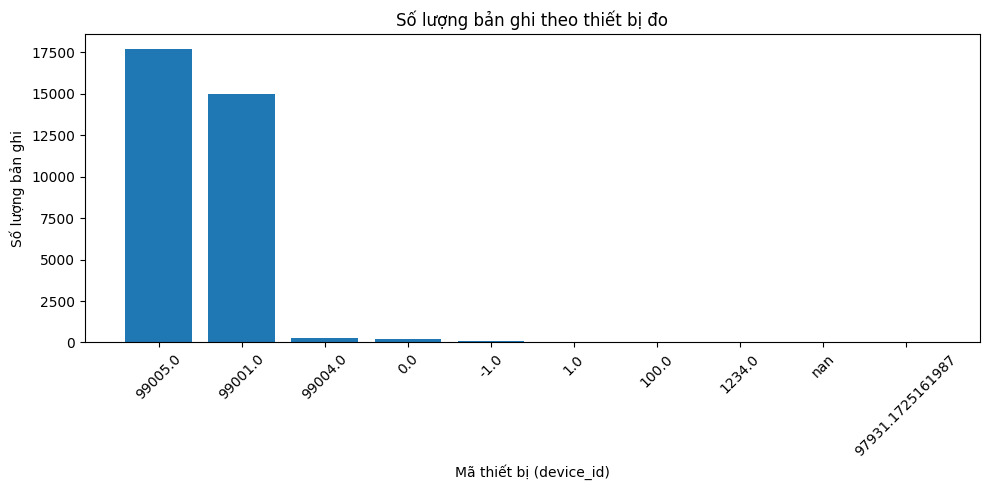

In [26]:
device_counts = (
    df["device_id"]
    .value_counts(dropna=False)
    .rename_axis("device_id")
    .reset_index(name="so_luong_ban_ghi")
)

display(device_counts)

plt.figure(figsize=(10, 5))
plt.bar(
    device_counts["device_id"].astype(str),
    device_counts["so_luong_ban_ghi"]
)

plt.title("Số lượng bản ghi theo thiết bị đo")
plt.xlabel("Mã thiết bị (device_id)")
plt.ylabel("Số lượng bản ghi")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 6 . Tiền xử lý dữ liệu

### 6.1 Loại bỏ dữ liệu trước ngày 03/01/2018

Theo yêu cầu đề bài, dữ liệu đo đạc chỉ chính xác kể từ ngày 03/01/2018 do cảm biến đã được điều chỉnh. Vì vậy, loại bỏ những bản ghi có thời điểm đo trước ngày này.

Đồng thời, loại bỏ các bản ghi không có thời điểm đo hợp lệ vì không thể xác định chúng có thuộc khoảng thời gian được chấp nhận hay không.

In [27]:
# Lưu số bản ghi trước khi xử lý
so_dong_ban_dau = len(df)

# Loại bỏ bản ghi không có thời điểm đo
df = df.dropna(subset=["time"]).copy()

# Giữ dữ liệu từ ngày 03/01/2018 trở đi
ngay_bat_dau = pd.Timestamp("2018-01-03")

df = df[df["time"] >= ngay_bat_dau].copy()
df = df.reset_index(drop=True)

print("Số dòng ban đầu:", so_dong_ban_dau)
print("Số dòng bị loại:", so_dong_ban_dau - len(df))
print("Số dòng còn lại:", len(df))
print("Thời điểm đo sớm nhất:", df["time"].min())
print("Thời điểm đo muộn nhất:", df["time"].max())

display(df.head())

Số dòng ban đầu: 33340
Số dòng bị loại: 31422
Số dòng còn lại: 1918
Thời điểm đo sớm nhất: 2018-01-03 13:11:07
Thời điểm đo muộn nhất: 2018-01-17 15:46:34


,id,device_id,co_level,humidity,temperature,time
0,31420.0,1.0,2.0,3.0,4.0,2018-01-03 13:11:07
1,31421.0,1.0,2.0,3.0,4.0,2018-01-03 13:15:10
2,31422.0,99005.0,58.0,26.0,0.0,2018-01-03 13:17:30
3,31423.0,99005.0,58.0,26.0,0.0,2018-01-03 13:19:21
4,31424.0,99005.0,58.0,26.0,0.0,2018-01-03 13:24:17


### 6.2 Tạo thuộc tính minutes từ cột time

Từ thuộc tính `time`, bóc tách thời điểm đo trong ngày và chuyển đổi thành số phút tính từ 00 giờ 00 phút. Thuộc tính mới được đặt tên là `minutes`.

Công thức tính:

`minutes = giờ × 60 + phút`

Ví dụ, thời điểm 08:30 tương ứng 510 phút và thời điểm 12:15 tương ứng 735 phút. Thuộc tính này được sử dụng làm trục hoành khi vẽ các biểu đồ phân tán.

In [28]:
df["minutes"] = (
    df["time"].dt.hour * 60
    + df["time"].dt.minute
)

display(
    df[[
        "id",
        "device_id",
        "time",
        "minutes",
        "co_level",
        "humidity",
        "temperature"
    ]].head(10)
)

,id,device_id,time,minutes,co_level,humidity,temperature
0,31420.0,1.0,2018-01-03 13:11:07,791,2.0,3.0,4.0
1,31421.0,1.0,2018-01-03 13:15:10,795,2.0,3.0,4.0
2,31422.0,99005.0,2018-01-03 13:17:30,797,58.0,26.0,0.0
3,31423.0,99005.0,2018-01-03 13:19:21,799,58.0,26.0,0.0
4,31424.0,99005.0,2018-01-03 13:24:17,804,58.0,26.0,0.0
5,31425.0,99005.0,2018-01-03 13:29:13,809,60.0,26.0,0.0
6,31426.0,99005.0,2018-01-03 13:34:10,814,64.0,26.0,0.0
7,31427.0,99005.0,2018-01-03 14:05:34,845,60.0,27.0,0.0
8,31428.0,99005.0,2018-01-03 14:10:43,850,60.0,27.0,0.0
9,31429.0,99005.0,2018-01-03 14:15:39,855,60.0,27.0,0.0


### 6.3 Vẽ đồ thị phân tán nồng độ khí CO theo minutes

Sử dụng biểu đồ phân tán để biểu diễn nồng độ khí CO (`co_level`) theo thời điểm đo trong ngày (`minutes`). Trục hoành thể hiện số phút tính từ đầu ngày, trục tung thể hiện nồng độ khí CO.

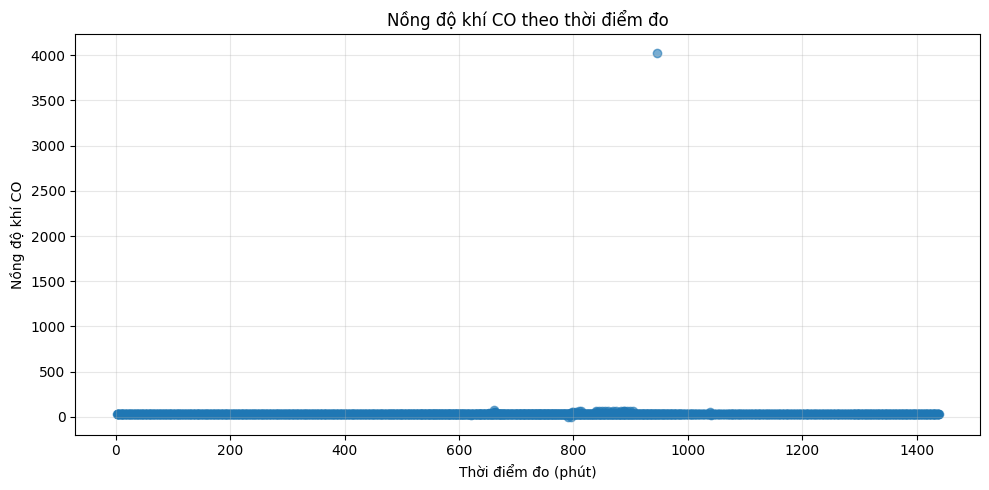

In [29]:
plt.figure(figsize=(10, 5))

plt.scatter(
    df["minutes"],
    df["co_level"],
    alpha=0.6
)

plt.title("Nồng độ khí CO theo thời điểm đo")
plt.xlabel("Thời điểm đo (phút)")
plt.ylabel("Nồng độ khí CO")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 6.4 Vẽ đồ thị phân tán độ ẩm theo minutes

Vẽ biểu đồ phân tán biểu diễn độ ẩm (`humidity`) theo thời điểm đo trong ngày (`minutes`). Biểu đồ giúp quan sát sự phân bố của độ ẩm tại các thời điểm đo khác nhau trong tập dữ liệu hợp lệ.

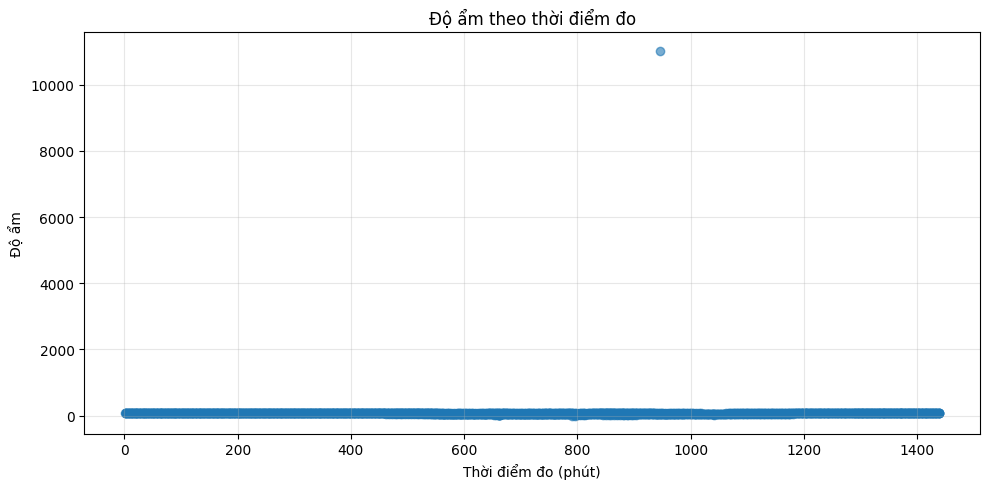

In [30]:
plt.figure(figsize=(10, 5))

plt.scatter(
    df["minutes"],
    df["humidity"],
    alpha=0.6
)

plt.title("Độ ẩm theo thời điểm đo")
plt.xlabel("Thời điểm đo (phút)")
plt.ylabel("Độ ẩm")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 6.5 Vẽ đồ thị phân tán nhiệt độ theo minutes

Vẽ biểu đồ phân tán biểu diễn nhiệt độ (`temperature`) theo thời điểm đo trong ngày (`minutes`). Qua biểu đồ, quan sát sự phân bố và biến động của nhiệt độ theo thời điểm đo đạc.

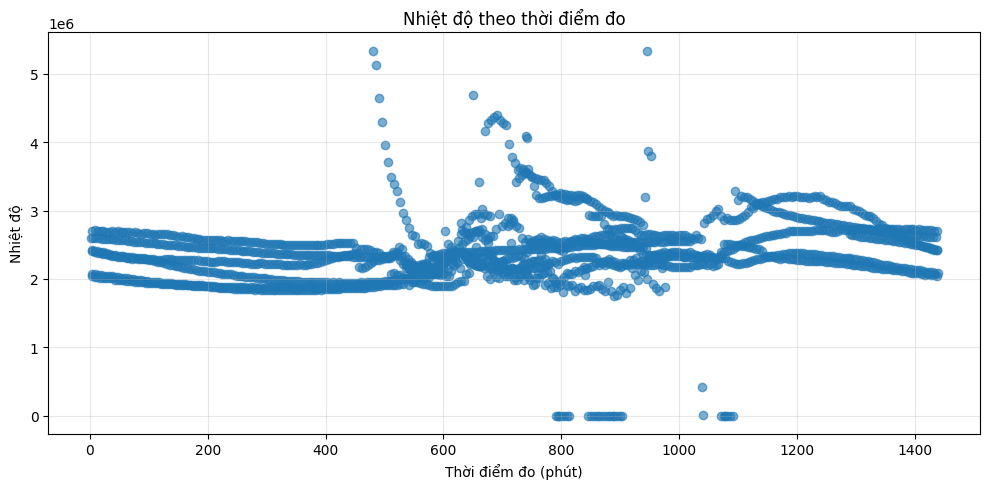

In [31]:
plt.figure(figsize=(10, 5))

plt.scatter(
    df["minutes"],
    df["temperature"],
    alpha=0.6
)

plt.title("Nhiệt độ theo thời điểm đo")
plt.xlabel("Thời điểm đo (phút)")
plt.ylabel("Nhiệt độ")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 6.6 Kiểm tra và lưu dữ liệu sau tiền xử lý

Sau khi hoàn thành các thao tác, kiểm tra lại kích thước dữ liệu, các thuộc tính, giá trị thiếu và thời điểm đo sớm nhất. Cuối cùng, lưu tập dữ liệu đã xử lý thành tệp Excel để phục vụ các bước phân tích tiếp theo.

In [32]:
print("Kích thước dữ liệu sau tiền xử lý:", df.shape)

print("\nThông tin dữ liệu:")
df.info()

print("\nSố lượng giá trị thiếu:")
display(df.isnull().sum().to_frame("So_luong_rong"))

print("\nThời điểm đo sớm nhất:", df["time"].min())

df.to_excel(
    "/content/tb_tracking_processed.xlsx",
    index=False
)

print("Đã lưu file tb_tracking_processed.xlsx")

Kích thước dữ liệu sau tiền xử lý: (1918, 7)

Thông tin dữ liệu:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1918 entries, 0 to 1917
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   id           1918 non-null   float64       
 1   device_id    1918 non-null   float64       
 2   co_level     1918 non-null   float64       
 3   humidity     1918 non-null   float64       
 4   temperature  1918 non-null   float64       
 5   time         1918 non-null   datetime64[ns]
 6   minutes      1918 non-null   int32         
dtypes: datetime64[ns](1), float64(5), int32(1)
memory usage: 97.5 KB

Số lượng giá trị thiếu:


,So_luong_rong
id,0
device_id,0
co_level,0
humidity,0
temperature,0
time,0
minutes,0



Thời điểm đo sớm nhất: 2018-01-03 13:11:07
Đã lưu file tb_tracking_processed.xlsx
